In [38]:
%load_ext autoreload
%autoreload 2

import os, sys
import pandas as pd
from datetime import datetime

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [39]:
from src.workflows.evaluation_workflow import EvaluateState, EvaluateWorkflow
from src.agents.support_agent import get_support_agent, SupportState, WorkflowSettings

In [40]:
df = pd.read_csv("../data/transactions.csv", index_col="transaction_id", parse_dates=["transaction_date"])
df.head()

,transaction_date,transaction_type,category,amount_ngn,payment_channel,description,suspicious_flag
transaction_id,,,,,,,
TXN0001,2026-04-13,Expense,Utilities,24563.25,POS,Utilities transaction,0
TXN0002,2026-09-28,Expense,Bank Charges,11339.64,Direct Debit,Bank Charges transaction,0
TXN0003,2026-04-17,Income,Sales,16232.84,Bank Transfer,Sales transaction,0
TXN0004,2026-03-13,Expense,Utilities,3152.87,Direct Debit,Utilities transaction,0
TXN0005,2026-07-08,Income,Sales,18004.45,Cash,Sales transaction,1


In [44]:
agent = get_support_agent(collections=["evaluation"], settings=WorkflowSettings(online=False))
workflow = EvaluateWorkflow(data=df, agent=agent)

In [45]:
result = await workflow.invoke(EvaluateState(), save=True)
result

[2026-10-20 13:46:44] [INFO] [EvaluateWorkflow] - [Invoked]
[2026-10-20 13:46:44] [INFO] [Knowledge] - [Deleted document with id eval from vector store]
[2026-10-20 13:46:48] [INFO] [Knowledge] - [Ingested dataframe with id eval into vector store]
[2026-10-20 13:46:48] [INFO] [EvaluateWorkflow] - [Generating answer for question: How mush did the business make?]
[2026-10-20 13:46:48] [INFO] [SupportAgent] - [Guardrailing message]
[2026-10-20 13:46:51] [INFO] [SearchWorkflow] - [Invoked]
[2026-10-20 13:46:51] [INFO] [Knowledge] - [Looking for documents]
[2026-10-20 13:46:53] [INFO] [SearchWorkflow] - [Retrieved Documents]
[2026-10-20 13:46:56] [INFO] [SearchWorkflow] - [Invoked]
[2026-10-20 13:46:56] [INFO] [Knowledge] - [Looking for documents]
[2026-10-20 13:46:56] [INFO] [SearchWorkflow] - [Retrieved Documents]
[2026-10-20 13:46:59] [INFO] [SearchWorkflow] - [Invoked]
[2026-10-20 13:46:59] [INFO] [Knowledge] - [Looking for documents]
[2026-10-20 13:46:59] [INFO] [SearchWorkflow] - [Ret

[EvaluationResult(query='How mush did the business make?', expected_answer=np.float64(5462275.369999999), generated_answer='Based on the available transaction records for Jan-Sep 2026, here is the financial summary:\n\n**Total Revenue:** NGN 484,111.10\n**Total Expenses:** NGN 214,111.10\n**Net Profit:** NGN 269,999.99 (approx. NGN 270,000)\n\n**Key Figures (Jan-Sep 2026):**\n*   **Total Income:** NGN 484,111.10 [T1, T2, T3]\n*   **Total Expenses:** NGN 214,111.10 [T1, T2, T3]\n*   **Net Profit:** NGN 269,999.99\n\n**Next Step:**\nWould you like a breakdown of your highest expenses or a monthly profit trend to see which months performed best?', evaluation=Evaluation(relevance=1.0, faithfulness=0.0, correctness=0.0, coherence=1.0, issues='The generated answer provides financial figures (Total Revenue: 484,111.10, Total Expenses: 214,111.10, Net Profit: 269,999.99) that are completely absent from the knowledge base and do not match the expected answer (5462275.37). The AI hallucinated th

In [47]:
eval_df = pd.read_csv("../data/evals/20_10_2026_13_48_04.csv")
eval_df

,query,expected_answer,generated_answer,relevance,faithfulness,correctness,coherence,issues
0,How mush did the business make?,5462275.369999999,Based on the available transaction records for...,1.0,0.0,0.00,1.0,The generated answer provides financial figure...
1,How mush did the business spend?,2545844.26,Based on the transaction records for Jan-Sep 2...,1.0,0.0,0.00,1.0,The generated answer provides a total expense ...
2,What did the business spend money on?,"<ArrowStringArray>\n[ 'Utilities', '...",The business spent money across several operat...,1.0,0.5,0.75,1.0,The generated answer includes a 'Total Spend' ...
3,What is the net cashflow,2916431.1099999994,The net cash flow for the business from Januar...,1.0,0.0,0.00,1.0,The generated answer provides figures (Net Cas...
4,Which category generates the most revenue,category\nCustomer Payment 1391548.21\nOthe...,The category that generates the most revenue i...,1.0,0.5,1.00,1.0,The generated answer includes several claims n...


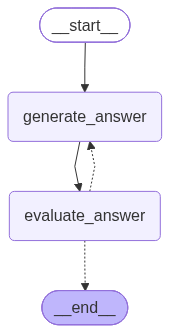

In [49]:
workflow.graph